# ML4Health — Part A: Data Extraction & Cohort Construction

**COMP90089 · Group 28 **





## 1. Setup



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick



RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

PALETTE = ["#1E2761", "#3F51B5", "#F4B942", "#028090", "#B85042", "#5A6182",
           "#00A896", "#990011"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 11})

In [4]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
PROJECT_ID = "ml-for-health-506411"          # <-- your billing project
HOSP    = "physionet-data.mimiciv_3_1_hosp"
ICU     = "physionet-data.mimiciv_3_1_icu"
DERIVED = "physionet-data.mimiciv_3_1_derived"

client = bigquery.Client(project=PROJECT_ID)
def run(sql):
    return client.query(sql).to_dataframe()


## 2. Raw extraction

We pull **one row per ICU stay** (not yet deduplicated — we do that explicitly in Section 3 so the
exclusions are visible and auditable). First-day physiology comes from the v3.1 `first_day_*`
concept tables; lactate from `first_day_bg`; severity from `first_day_sofa`; comorbidity from
`charlson`. Sensitive attributes (`race`, `sex`, `insurance`) are carried for the audit only.

Crucially we also select `ie.intime` — the ICU admission time — so we can order a patient's stays
chronologically and keep the **first** one, instead of ordering by `stay_id` (which is an arbitrary
surrogate key, not a timeline).

In [5]:
def extract_raw():
    query = f"""
    SELECT
        ie.subject_id, ie.hadm_id, ie.stay_id,
        ie.intime, ie.outtime,
        p.gender                    AS sex,
        a.race                      AS race,
        a.insurance                 AS insurance,
        a.hospital_expire_flag      AS mortality,
        p.anchor_age                AS age,
        vs.heart_rate_mean, vs.sbp_min, vs.spo2_min, vs.resp_rate_mean,
        lab.creatinine_max, lab.platelets_min, lab.bun_max, lab.wbc_max,
        gcs.gcs_min,
        bg.lactate_max,
        sofa.sofa                       AS sofa,
        cci.charlson_comorbidity_index  AS charlson
    FROM `{ICU}.icustays` ie
    JOIN `{HOSP}.patients`   p ON ie.subject_id = p.subject_id
    JOIN `{HOSP}.admissions` a ON ie.hadm_id   = a.hadm_id
    LEFT JOIN `{DERIVED}.first_day_vitalsign` vs   ON ie.stay_id = vs.stay_id
    LEFT JOIN `{DERIVED}.first_day_lab`       lab  ON ie.stay_id = lab.stay_id
    LEFT JOIN `{DERIVED}.first_day_gcs`       gcs  ON ie.stay_id = gcs.stay_id
    LEFT JOIN `{DERIVED}.first_day_bg`        bg   ON ie.stay_id = bg.stay_id
    LEFT JOIN `{DERIVED}.first_day_sofa`      sofa ON ie.stay_id = sofa.stay_id
    LEFT JOIN `{DERIVED}.charlson`            cci  ON ie.hadm_id = cci.hadm_id
    """
    return run(query)

print("2. RAW EXTRACTION")
raw = extract_raw()
print("Raw ICU stays pulled:", f"{len(raw):,}")
print("Unique patients:", f"{raw['subject_id'].nunique():,}")
raw.head()

2. RAW EXTRACTION
Raw ICU stays pulled: 94,458
Unique patients: 65,366


,subject_id,hadm_id,stay_id,intime,outtime,sex,race,insurance,mortality,age,...,spo2_min,resp_rate_mean,creatinine_max,platelets_min,bun_max,wbc_max,gcs_min,lactate_max,sofa,charlson
0,12616428,20416287,35186964,2189-03-31 13:24:24,2189-04-01 02:35:13,F,UNKNOWN,Medicaid,0,21,...,92.000,18.000,0.700,128.000,11.000,11.900,13.000,NaN,3,0
1,12774362,28954607,37164831,2151-07-30 02:20:35,2151-08-07 18:01:09,M,PORTUGUESE,Medicare,0,21,...,86.000,15.979,3.700,245.000,31.000,9.800,15.000,1.900,4,3
2,15301569,25599780,33337491,2146-05-27 02:36:00,2146-06-12 18:41:04,M,UNKNOWN,Private,0,24,...,87.000,17.741,NaN,NaN,NaN,NaN,6.000,NaN,3,0
3,15740995,23410432,38684606,2120-06-28 17:57:04,2120-06-29 22:16:25,M,UNABLE TO OBTAIN,Private,0,18,...,89.000,16.222,0.700,450.000,16.000,17.600,14.000,NaN,1,0
4,17295976,29633749,33539374,2141-10-27 11:12:46,2141-10-27 14:46:16,M,WHITE,Private,0,23,...,100.000,18.882,0.500,313.000,14.000,12.300,15.000,1.200,0,0


## 3. Cohort construction with an auditable flow

We apply exclusions **step by step** and record the count after each, so the cohort flow diagram
and the report's Methods section come straight from the code. Steps:

1. Start from all raw ICU stays.
2. Keep adults (age ≥ 18).
3. **Fix problem 1** — keep each patient's **first ICU stay by `intime`**, then
   `drop_duplicates("subject_id")`. This guarantees one row per patient, drawn from a single stay,
   ordered by real admission time rather than by `stay_id`.

In [6]:
flow = []          # (step description, rows remaining, patients remaining)
def record(df, label):
    flow.append((label, len(df), df["subject_id"].nunique()))
    print(f"{label:<45} rows={len(df):>7,}  patients={df['subject_id'].nunique():>7,}")

print("3. COHORT FLOW")
df = raw.copy()
record(df, "0. Raw ICU stays")

df = df[df["age"] >= 18].copy()
record(df, "1. Adults (age >= 18)")


df["intime"] = pd.to_datetime(df["intime"])
df = df.sort_values(["subject_id", "intime"])           # chronological, not stay_id
df = df.drop_duplicates(subset="subject_id", keep="first").reset_index(drop=True)
record(df, "2. First ICU stay per patient (by intime)")

print(f"\nFinal cohort: {len(df):,} unique patients "
      f"(removed {len(raw)-len(df):,} rows across all steps).")

3. COHORT FLOW
0. Raw ICU stays                              rows= 94,458  patients= 65,366
1. Adults (age >= 18)                         rows= 94,458  patients= 65,366
2. First ICU stay per patient (by intime)     rows= 65,366  patients= 65,366

Final cohort: 65,366 unique patients (removed 29,092 rows across all steps).


In [7]:
# Normalise label + sensitive attributes on the deduplicated cohort
df["mortality"] = pd.to_numeric(df["mortality"], errors="coerce").astype(int)
df["insurance"] = df["insurance"].replace({"No charge": "Other"})   # n<10, unstable

RACE_ORDER = ["White","Black","Hispanic","Asian","Other","Unknown"]
def order_races(idx):
    return [r for r in RACE_ORDER if r in list(idx)] + \
           [r for r in idx if r not in RACE_ORDER]

def bucket_race(series):
    r = series.astype(str).str.upper().str.strip()
    def b(x):
        if x in ("NAN","NONE",""): return "Unknown"
        if "WHITE" in x: return "White"
        if "BLACK" in x or "AFRICAN" in x: return "Black"
        if "HISPANIC" in x or "LATINO" in x: return "Hispanic"
        if "ASIAN" in x: return "Asian"
        if "UNKNOWN" in x or "UNABLE" in x or "DECLINED" in x: return "Unknown"
        return "Other"
    return r.map(b)

df["race"] = bucket_race(df["race"])
print("Overall mortality:", round(df["mortality"].mean(), 3))
print("\nRace buckets:"); print(df["race"].value_counts().reindex(order_races(df["race"].unique())))

Overall mortality: 0.108

Race buckets:
race
White       42871
Black        6016
Hispanic     2284
Asian        1981
Other        2833
Unknown      9381
Name: count, dtype: int64


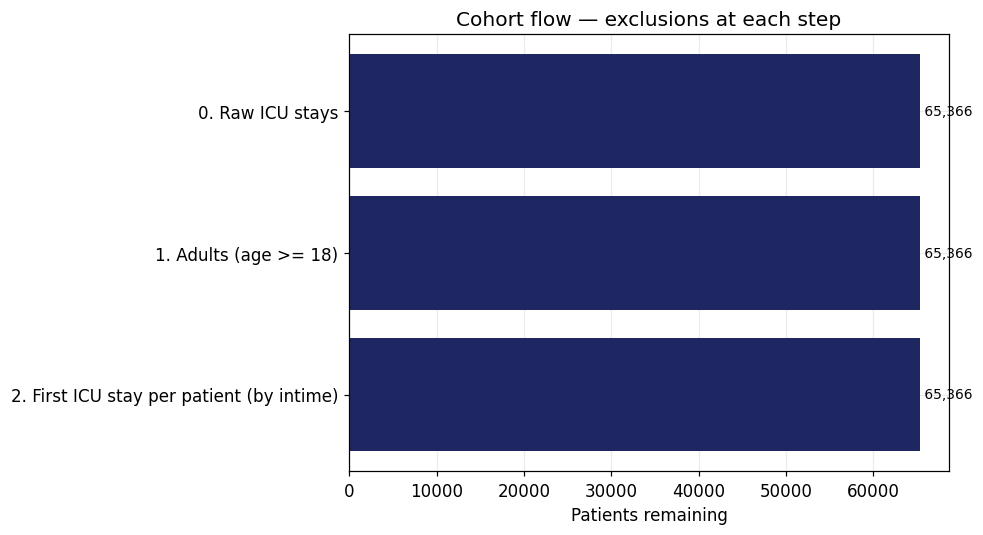

In [8]:
# Cohort flow diagram
fig, ax = plt.subplots(figsize=(9, 5))
labels = [f[0] for f in flow]; patients = [f[2] for f in flow]
ax.barh(range(len(flow)), patients, color=PALETTE[0])
ax.set_yticks(range(len(flow))); ax.set_yticklabels(labels)
ax.invert_yaxis(); ax.set_xlabel("Patients remaining")
ax.set_title("Cohort flow — exclusions at each step")
for i, v in enumerate(patients):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    if i > 0:
        drop = flow[i-1][2] - v
        if drop: ax.text(v*0.5, i, f"-{drop:,}", va="center", ha="center",
                         color="white", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Feature dictionary

In [9]:
NUMERIC = ["age","heart_rate_mean","sbp_min","spo2_min","resp_rate_mean",
           "creatinine_max","platelets_min","bun_max","wbc_max","gcs_min",
           "lactate_max","sofa","charlson"]
NUMERIC = [c for c in NUMERIC if c in df.columns]
SENSITIVE = ["race","sex","insurance"]

# Measurement-missingness indicators for labs that aren't drawn on everyone.
# "Was it measured?" is itself informative (sicker patients get a blood gas).
for col in ["lactate_max","sofa","charlson"]:
    if col in df.columns:
        df[col + "_measured"] = df[col].notna().astype(int)

print("4. FEATURE DICTIONARY")
print("Numeric features:", NUMERIC)
print("Sensitive attributes:", SENSITIVE)
print("Added measurement indicators:",
      [c for c in df.columns if c.endswith("_measured")])
print(df[NUMERIC].describe().T.round(2), "feature summary stats")
df[NUMERIC].describe().T

4. FEATURE DICTIONARY
Numeric features: ['age', 'heart_rate_mean', 'sbp_min', 'spo2_min', 'resp_rate_mean', 'creatinine_max', 'platelets_min', 'bun_max', 'wbc_max', 'gcs_min', 'lactate_max', 'sofa', 'charlson']
Sensitive attributes: ['race', 'sex', 'insurance']
Added measurement indicators: ['lactate_max_measured', 'sofa_measured', 'charlson_measured']
                    count    mean    std    min     25%     50%     75%  \
age             65366.000  63.415 17.071 18.000  53.000  65.000  76.000   
heart_rate_mean 65282.000  84.111 15.842 28.500  73.000  82.559  93.918   
sbp_min         65261.000  93.079 17.694  0.108  82.500  92.000 103.000   
spo2_min        65210.000  91.684  6.560  1.000  91.000  93.000  95.000   
resp_rate_mean  65171.000  19.046  3.786  6.000  16.400  18.385  21.014   
creatinine_max  64759.000   1.455  1.606  0.100   0.800   1.000   1.400   
platelets_min   64675.000 190.975 97.933  5.000 127.000 178.000 238.000   
bun_max         64765.000  26.218 21.836  1.0

,count,mean,std,min,25%,50%,75%,max
age,65366.000,63.415,17.071,18.000,53.000,65.000,76.000,91.000
heart_rate_mean,65282.000,84.111,15.842,28.500,73.000,82.559,93.918,174.741
sbp_min,65261.000,93.079,17.694,0.108,82.500,92.000,103.000,218.000
spo2_min,65210.000,91.684,6.560,1.000,91.000,93.000,95.000,100.000
resp_rate_mean,65171.000,19.046,3.786,6.000,16.400,18.385,21.014,48.000
creatinine_max,64759.000,1.455,1.606,0.100,0.800,1.000,1.400,43.000
platelets_min,64675.000,190.975,97.933,5.000,127.000,178.000,238.000,2001.000
bun_max,64765.000,26.218,21.836,1.000,14.000,19.000,30.000,261.000
wbc_max,64676.000,14.019,11.739,0.100,8.800,12.300,16.800,614.800
gcs_min,65088.000,13.702,2.658,3.000,14.000,15.000,15.000,15.000


## 5. Missingness — every feature, every sensitive attribute

Extends the earlier lactate-only check. Differential missingness across subgroups is itself a
fairness concern: groups measured less often get more imputed (less informative) features, which
can quietly degrade the model for them. We give (a) overall missingness per feature, and (b)
missingness of each feature broken down by race, sex and insurance.

5. MISSINGNESS


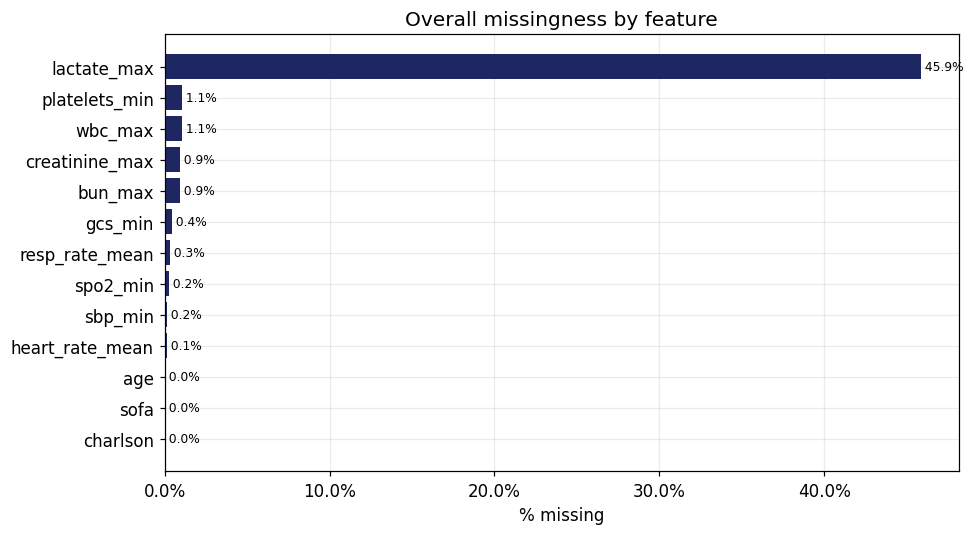

lactate_max       45.900
platelets_min      1.100
wbc_max            1.100
creatinine_max     0.900
bun_max            0.900
gcs_min            0.400
resp_rate_mean     0.300
spo2_min           0.200
sbp_min            0.200
heart_rate_mean    0.100
age                0.000
sofa               0.000
charlson           0.000
dtype: float64


In [10]:
print("5. MISSINGNESS")
# overall missingness per feature
miss = df[NUMERIC].isna().mean().sort_values(ascending=False)*100
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(miss.index, miss.values, color=PALETTE[0])
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.invert_yaxis(); ax.set_title("Overall missingness by feature"); ax.set_xlabel("% missing")
for i,v in enumerate(miss.values): ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print(miss.round(1))

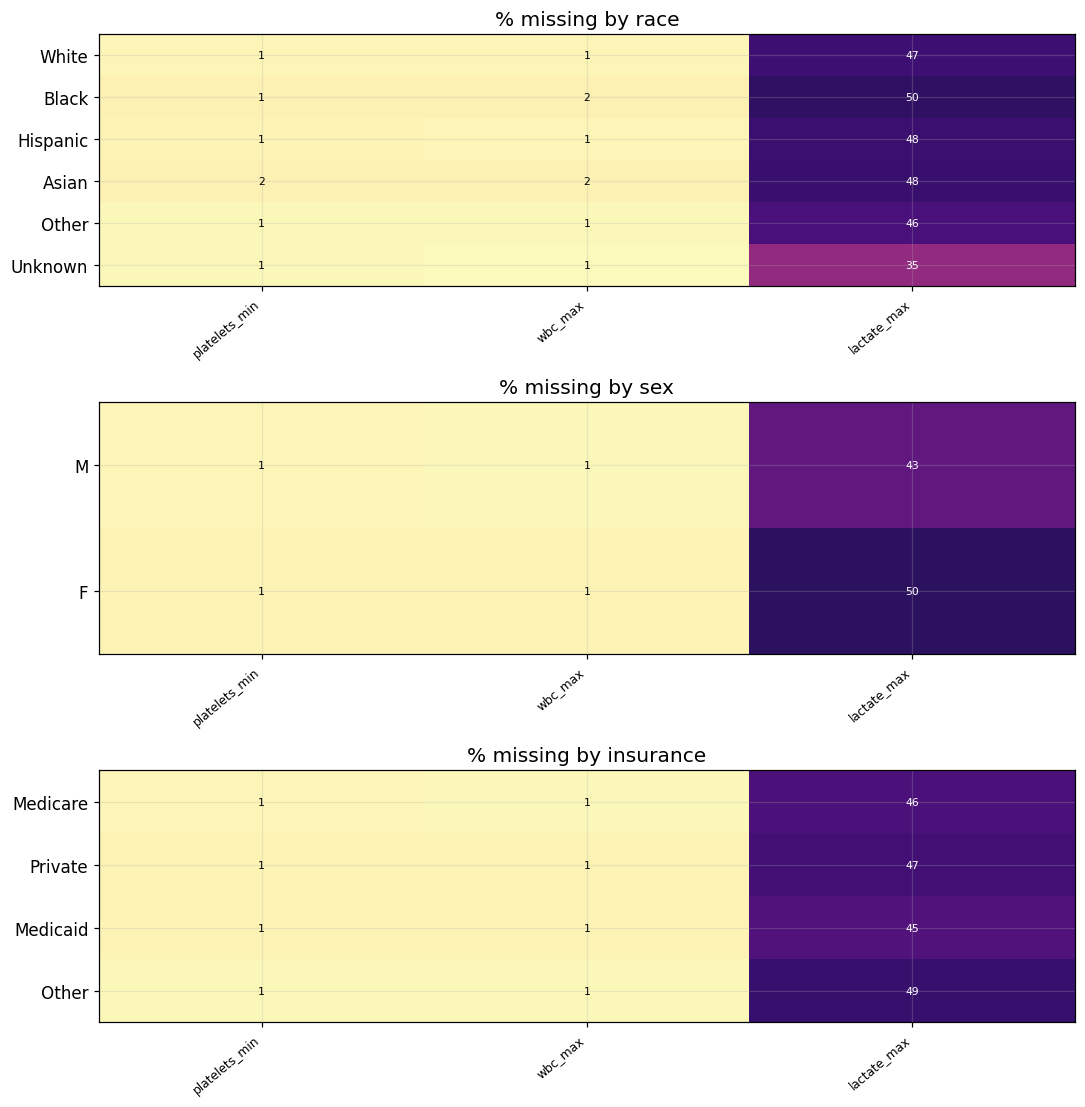

In [11]:
# missingness of each feature by each sensitive attribute (heatmaps)
sparse = [c for c in NUMERIC if df[c].isna().mean() > 0.01]  # only features that are ever missing
if not sparse:
    print("No feature exceeds 1% missingness — nothing to break down by subgroup.")
else:
    fig, axes = plt.subplots(len(SENSITIVE), 1, figsize=(10, 3.4*len(SENSITIVE)))
    if len(SENSITIVE)==1: axes=[axes]
    for ax, attr in zip(axes, SENSITIVE):
        grp_order = order_races(df[attr].unique()) if attr=="race" else \
                    list(df.groupby(attr).size().sort_values(ascending=False).index)
        M = (df.groupby(attr)[sparse].apply(lambda g: g.isna().mean())*100).reindex(grp_order)
        im = ax.imshow(M.values, cmap="magma_r", aspect="auto", vmin=0, vmax=max(60, M.values.max()))
        ax.set_xticks(range(len(sparse))); ax.set_xticklabels(sparse, rotation=40, ha="right", fontsize=8)
        ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index)
        ax.set_title(f"% missing by {attr}")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v=M.values[i,j]
                if not np.isnan(v):
                    ax.text(j,i,f"{v:.0f}",ha="center",va="center",
                            color="white" if v>30 else "black", fontsize=7)
    plt.tight_layout(); plt.show()

In [12]:
# Interpretation — differential missingness
print("HOW TO READ: each row is a subgroup, each column a feature; the number is % missing.")
print("Even columns = data collected evenly across groups. A column that is dark for one group")
print("only = that group is measured less, so its rows lean more on imputation.\n")
for attr in SENSITIVE:
    for col in [c for c in NUMERIC if df[c].isna().mean()>0.01]:
        by = df.groupby(attr)[col].apply(lambda s: s.isna().mean())*100
        spread = by.max()-by.min()
        if spread >= 10:
            print(f"- {col} by {attr}: {spread:.0f}pt spread "
                  f"(highest {by.idxmax()} {by.max():.0f}%, lowest {by.idxmin()} {by.min():.0f}%). "
                  "Flag in report as differential data quality.")
print("\n(If nothing prints above, no feature/attribute combination exceeds a 10pt spread — "
      "measurement is fairly even, which is itself worth stating.)")

HOW TO READ: each row is a subgroup, each column a feature; the number is % missing.
Even columns = data collected evenly across groups. A column that is dark for one group
only = that group is measured less, so its rows lean more on imputation.

- lactate_max by race: 15pt spread (highest Black 50%, lowest Unknown 35%). Flag in report as differential data quality.

(If nothing prints above, no feature/attribute combination exceeds a 10pt spread — measurement is fairly even, which is itself worth stating.)


## 6. Cohort description (hand-off summary)


In [13]:
print("6. COHORT DESCRIPTION")
summary = {}
for col in SENSITIVE:
    g = df.groupby(col)["mortality"].agg(n="size", mortality_rate="mean")
    if col=="race": g = g.reindex(order_races(g.index))
    summary[col] = g
    print(f"\n=== {col} ==="); print(g.round(3))

overall = df["mortality"].mean()
print(f"\nOverall: {len(df):,} patients, {int(df['mortality'].sum()):,} deaths "
      f"({overall*100:.1f}%).")

6. COHORT DESCRIPTION

=== race ===
              n  mortality_rate
race                           
White     42871           0.095
Black      6016           0.091
Hispanic   2284           0.075
Asian      1981           0.107
Other      2833           0.093
Unknown    9381           0.193

=== sex ===
         n  mortality_rate
sex                       
F    28646           0.113
M    36720           0.105

=== insurance ===
               n  mortality_rate
insurance                       
Medicaid    9353           0.091
Medicare   34464           0.131
Other       1740           0.072
Private    18447           0.069

Overall: 65,366 patients, 7,086 deaths (10.8%).


In [14]:
# Interpretation — what the cohort looks like after the dedup fix
print(f"COHORT (post-fix): {len(df):,} unique patients, one row each from their FIRST ICU stay.")
print(f"MORTALITY: {overall*100:.1f}% overall — a ~{round(1/overall)}:1 imbalance, so downstream")
print("evaluation must lean on AUPRC / FNR, not accuracy.\n")
for col in SENSITIVE:
    g = summary[col].dropna()
    hi, lo = g['mortality_rate'].idxmax(), g['mortality_rate'].idxmin()
    print(f"{col}: {len(g)} groups; highest mortality {hi} {g.loc[hi,'mortality_rate']*100:.1f}%, "
          f"lowest {lo} {g.loc[lo,'mortality_rate']*100:.1f}% "
          f"(spread {(g.loc[hi,'mortality_rate']-g.loc[lo,'mortality_rate'])*100:.1f}pt).")
    if g.loc[hi,'mortality_rate'] > 1.4*overall:
        print(f"   NOTE: {hi} sits well above the cohort average — likely reflects who ends up in")
        print(f"   that group (sicker/emergency admissions), a cohort feature for B/D to adjust for.")

COHORT (post-fix): 65,366 unique patients, one row each from their FIRST ICU stay.
MORTALITY: 10.8% overall — a ~9:1 imbalance, so downstream
evaluation must lean on AUPRC / FNR, not accuracy.

race: 6 groups; highest mortality Unknown 19.3%, lowest Hispanic 7.5% (spread 11.8pt).
   NOTE: Unknown sits well above the cohort average — likely reflects who ends up in
   that group (sicker/emergency admissions), a cohort feature for B/D to adjust for.
sex: 2 groups; highest mortality F 11.3%, lowest M 10.5% (spread 0.9pt).
insurance: 4 groups; highest mortality Medicare 13.1%, lowest Private 6.9% (spread 6.2pt).


## 7. Export the clean cohort



In [15]:
KEEP = ["subject_id","hadm_id","stay_id","intime","outtime",
        "sex","race","insurance","mortality"] + NUMERIC + \
       [c for c in df.columns if c.endswith("_measured")]
KEEP = [c for c in dict.fromkeys(KEEP) if c in df.columns]
cohort = df[KEEP].copy()

cohort.to_parquet("ml4health_cohort.parquet", index=False)
cohort.to_csv("ml4health_cohort.csv", index=False)
print("Shape:", cohort.shape)
print("\nColumns:", list(cohort.columns))
print("\nDownstream notebooks load with:")
print('    df = pd.read_parquet("ml4health_cohort.parquet")')
cohort.head()

Shape: (65366, 25)

Columns: ['subject_id', 'hadm_id', 'stay_id', 'intime', 'outtime', 'sex', 'race', 'insurance', 'mortality', 'age', 'heart_rate_mean', 'sbp_min', 'spo2_min', 'resp_rate_mean', 'creatinine_max', 'platelets_min', 'bun_max', 'wbc_max', 'gcs_min', 'lactate_max', 'sofa', 'charlson', 'lactate_max_measured', 'sofa_measured', 'charlson_measured']

Downstream notebooks load with:
    df = pd.read_parquet("ml4health_cohort.parquet")


,subject_id,hadm_id,stay_id,intime,outtime,sex,race,insurance,mortality,age,...,platelets_min,bun_max,wbc_max,gcs_min,lactate_max,sofa,charlson,lactate_max_measured,sofa_measured,charlson_measured
0,10000032,29079034,39553978,2180-07-23 14:00:00,2180-07-23 23:50:47,F,White,Medicaid,0,52,...,94.000,33.000,4.100,14.000,NaN,10,3,0,1,1
1,10000690,25860671,37081114,2150-11-02 19:37:00,2150-11-06 17:03:17,F,White,Medicare,0,86,...,199.000,21.000,7.500,12.000,NaN,5,5,0,1,1
2,10000980,26913865,39765666,2189-06-27 08:42:00,2189-06-27 20:38:27,F,Black,Medicare,0,73,...,197.000,38.000,5.400,15.000,NaN,2,8,0,1,1
3,10001217,24597018,37067082,2157-11-20 19:18:02,2157-11-21 22:08:00,F,White,Private,0,55,...,283.000,10.000,19.000,15.000,NaN,0,1,0,1,1
4,10001725,25563031,31205490,2110-04-11 15:52:22,2110-04-12 23:59:56,F,White,Private,0,46,...,299.000,18.000,20.100,15.000,NaN,1,1,0,1,1


## Hand-off notes for the team

- **One row per patient**, first ICU stay by `intime` (problem 1 fixed). Do not re-deduplicate.
- **SOFA** and **Charlson** are included (problem 6 fixed), plus `*_measured` indicators.
- `NUMERIC` and `SENSITIVE` lists above are the agreed feature sets — B, keep them identical so the
  audit lines up.
- Missingness is characterised but **not imputed here** — B imputes inside the modelling pipeline
  (median imputer) so the train/val/test split can't leak.
- **B (next):** load the parquet, do the 60/20/20 split + 5-fold CV, add the SOFA-only baseline and
  XGBoost. **C/D** wait on B's split object.

### Generative AI declaration
State the tool used and that it was used only for brainstorming / planning / proofreading /
editing — **not** for drafting text, generating code, or generating content.